<div style="background-color:#3B195B;color:#FFFFFF;padding:24px;border-radius:12px;">
<h1 style="color:#FFFFFF;">Airports, Geography &amp; Wind</h1>
<p style="color:#E9D5FF;">IS 362 • Week 5 Assignment</p>
<p><strong>Precious Brown</strong></p>
</div>

# Investigating airport locations and weather with pandas

This notebook answers three questions using the assigned `nycflights13` CSV files. I inspect candidate answers, verify airport locations, and document data quality decisions before drawing conclusions.

1. Which airport is northernmost?
2. Which airport is easternmost?
3. Which New York area airport had the windiest weather on February 12, 2013?

The purple palette personalizes the charts. All explanations and results remain readable if a notebook viewer ignores HTML styling.

## 1. Setup and scope

I use Python and pandas for analysis and Matplotlib for visualization.

**Assumptions**

* The geographic answers describe airports represented in the supplied dataset, not a complete inventory of every U.S. airstrip or territory.
* Northernmost means the largest verified latitude.
* For the main easternmost answer, I compare locations from west to east across the United States, placing the Aleutian Islands west of mainland Alaska. I also report the answer obtained using the largest signed longitude, since these conventions differ.
* New York area airports are EWR, JFK, and LGA. “Windiest” means the highest mean recorded hourly wind speed for the local calendar day. I also compare maximum hourly speeds.
* Wind speeds are in **miles per hour**, as defined in the [official weather documentation](https://nycflights13.tidyverse.org/reference/weather.html). Missing or invalid speeds are excluded from aggregates, not replaced with zero.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# A consistent purple palette for all charts.
PURPLE = "#7C3AED"
DARK_PURPLE = "#3B195B"
LIGHT_PURPLE = "#C4B5FD"
PALE_PURPLE = "#FAF5FF"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": PALE_PURPLE,
    "axes.titlecolor": DARK_PURPLE, "axes.labelcolor": DARK_PURPLE,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "figure.dpi": 120,
})
pd.set_option("display.max_colwidth", 60)

## 2. Load the original data

Source: [assigned nycflights13 data directory](https://github.com/hadley/nycflights13/tree/master/data-raw).

The project includes unchanged copies of `airports.csv` and `weather.csv`, retrieved October 4, 2026. The loader uses those local files first, with a GitHub fallback if they are unavailable. All changes are made to working copies, preserving the original data.

In [2]:
BASE_URL = "https://raw.githubusercontent.com/hadley/nycflights13/master/data-raw/"

def load_csv(filename):
    local_file = Path("data") / filename
    source = local_file if local_file.exists() else BASE_URL + filename
    return pd.read_csv(source)

airports_raw = load_csv("airports.csv")
weather_raw = load_csv("weather.csv")
print(f"Airport rows: {len(airports_raw):,}")
print(f"Weather rows: {len(weather_raw):,}")
display(airports_raw.head())
display(weather_raw.head())

Airport rows: 1,458
Weather rows: 26,115


,faa,name,lat,lon,alt,tz,dst,tzone
0,04G,Lansdowne Airport,41.130472,-80.619583,1044,-5,A,America/New_York
1,06A,Moton Field Municipal Airport,32.460572,-85.680028,264,-6,A,America/Chicago
2,06C,Schaumburg Regional,41.989341,-88.101243,801,-6,A,America/Chicago
3,06N,Randall Airport,41.431912,-74.391561,523,-5,A,America/New_York
4,09J,Jekyll Island Airport,31.074472,-81.427778,11,-5,A,America/New_York


,origin,year,month,day,hour,temp,dewp,humid,wind_dir,wind_speed,wind_gust,precip,pressure,visib,time_hour
0,EWR,2013,1,1,1,39.02,26.06,59.37,270.0,10.35702,NaN,0.0,1012.0,10.0,2013-01-01T06:00:00Z
1,EWR,2013,1,1,2,39.02,26.96,61.63,250.0,8.05546,NaN,0.0,1012.3,10.0,2013-01-01T07:00:00Z
2,EWR,2013,1,1,3,39.02,28.04,64.43,240.0,11.50780,NaN,0.0,1012.5,10.0,2013-01-01T08:00:00Z
3,EWR,2013,1,1,4,39.92,28.04,62.21,250.0,12.65858,NaN,0.0,1012.2,10.0,2013-01-01T09:00:00Z
4,EWR,2013,1,1,5,39.02,28.04,64.43,260.0,12.65858,NaN,0.0,1011.9,10.0,2013-01-01T10:00:00Z


## 3. Inspect geographic candidates before accepting them

A descending latitude or longitude sort is a starting point, not proof. I inspect the top five results and check whether the locations make sense.

In [3]:
location_columns = ["faa", "name", "lat", "lon", "tzone"]
print("Five largest raw latitudes")
display(airports_raw.nlargest(5, "lat")[location_columns])
print("Five largest raw signed longitudes")
display(airports_raw.nlargest(5, "lon")[location_columns])

Five largest raw latitudes
Five largest raw signed longitudes


,faa,name,lat,lon,tzone
417,EEN,Dillant Hopkins Airport,72.270833,42.898333,NaN
230,BRW,Wiley Post Will Rogers Mem,71.285446,-156.766003,America/Anchorage
110,AIN,Wainwright Airport,70.638056,-159.994722,America/Anchorage
708,K03,Wainwright As,70.613378,-159.860350,America/Anchorage
152,ATK,Atqasuk Edward Burnell Sr Memorial Airport,70.467300,-157.436000,America/Anchorage


,faa,name,lat,lon,tzone
1290,SYA,Eareckson As,52.712275,174.113620,America/Anchorage
942,MYF,Montgomery Field,32.475900,117.759000,Asia/Chongqing
396,DVT,Deer Valley Municipal Airport,33.411700,112.457000,Asia/Chongqing
417,EEN,Dillant Hopkins Airport,72.270833,42.898333,NaN
444,EPM,Eastport Municipal Airport,44.910111,-67.012694,America/New_York


### Research and data decisions

| Record | Issue | Action and evidence |
|:--|:--|:--|
| EEN, Dillant Hopkins | The CSV places it at 72.270833° N, 42.898333° E. | Exclude this erroneous coordinate record from geographic rankings. The [City of Keene](https://keenenh.gov/airport/) identifies the airport in New Hampshire, and [FAA information reproduced by AirNav](https://www.airnav.com/airport/KEEN) places it near 42.8984° N, 72.2708° W. |
| MYF, Montgomery Field | Positive longitude and Asia/Chongqing time zone conflict with its location. | Exclude its unreliable coordinate record. The [City of San Diego](https://www.sandiego.gov/airports/montgomery) confirms this is a San Diego airport. |
| DVT, Deer Valley | Positive longitude and Asia/Chongqing time zone conflict with its location. | Exclude its unreliable coordinate record. The [airport operator's directions](https://www.deervalleyairport.com/about-dvt-airport/directions/) locate it in Phoenix, Arizona. |
| SYA, Eareckson | Positive longitude initially looks suspicious. | Retain it. The [Alaska Department of Environmental Conservation](https://dec.alaska.gov/Applications/SPAR/PublicMVC/CSP/SiteReport/65) places the station on Shemya Island and reports positive longitude around 174° E. |

I exclude the three unreliable records instead of guessing replacement values. Their verified cities are far south of Barrow and west of Eastport, so this exclusion does not hide a plausible winning candidate. This is a targeted review of extreme candidates, not a comprehensive audit of every airport. No other original airport values are changed.

In [4]:
excluded_codes = ["EEN", "MYF", "DVT"]
airports = airports_raw.loc[
    ~airports_raw["faa"].isin(excluded_codes)
].copy()
print("Excluded unreliable coordinate records:")
display(airports_raw.loc[airports_raw["faa"].isin(excluded_codes), location_columns])
print(f"Retained {len(airports):,} airport records.")

Excluded unreliable coordinate records:
Retained 1,455 airport records.


,faa,name,lat,lon,tzone
396,DVT,Deer Valley Municipal Airport,33.411700,112.457000,Asia/Chongqing
417,EEN,Dillant Hopkins Airport,72.270833,42.898333,NaN
942,MYF,Montgomery Field,32.475900,117.759000,Asia/Chongqing


## 4. Northernmost airport

After excluding the erroneous records, I sort by latitude again and display the five northernmost candidates.

Northernmost: BRW — Wiley Post Will Rogers Mem


,faa,name,lat,lon,tzone
230,BRW,Wiley Post Will Rogers Mem,71.285446,-156.766003,America/Anchorage
110,AIN,Wainwright Airport,70.638056,-159.994722,America/Anchorage
708,K03,Wainwright As,70.613378,-159.860350,America/Anchorage
152,ATK,Atqasuk Edward Burnell Sr Memorial Airport,70.467300,-157.436000,America/Anchorage
1363,UUK,Ugnu-Kuparuk Airport,70.330833,-149.597500,America/Anchorage


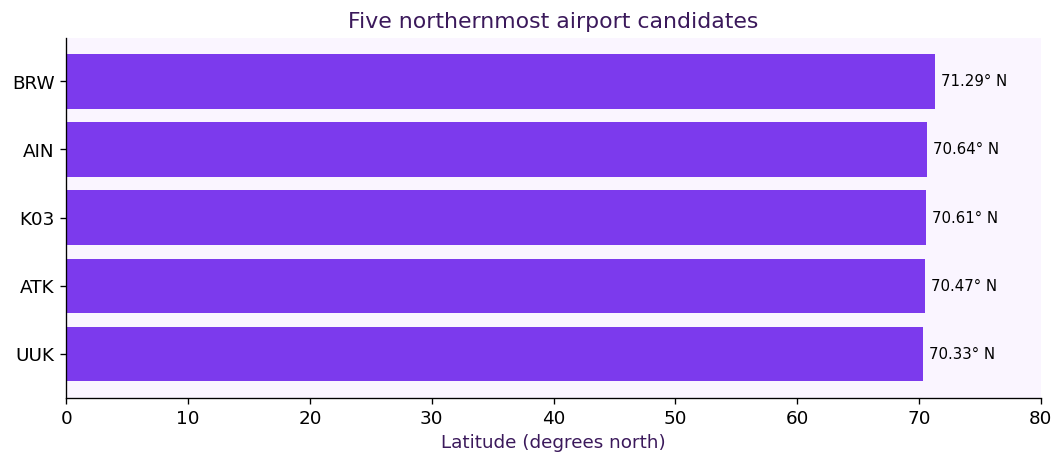

In [5]:
northernmost = airports.nlargest(5, "lat")[location_columns]
display(northernmost)
north_winner = northernmost.iloc[0]
print(f"Northernmost: {north_winner['faa']} — {north_winner['name']}")

fig, ax = plt.subplots(figsize=(9, 4))
plot_data = northernmost.sort_values("lat")
ax.barh(plot_data["faa"], plot_data["lat"], color=PURPLE)
ax.set(xlabel="Latitude (degrees north)", title="Five northernmost airport candidates")
ax.set_xlim(0, 80)
for i, value in enumerate(plot_data["lat"]):
    ax.text(value + 0.5, i, f"{value:.2f}° N", va="center", fontsize=9)
fig.tight_layout()
plt.show()

### Answer 1

**Wiley Post–Will Rogers Memorial Airport (BRW), in Utqiaġvik (formerly Barrow), Alaska**, is the northernmost airport in the reviewed dataset, at approximately **71.2854° N**.

The [Alaska DOT airport emergency plan, facility description, page 4-1](https://dot.alaska.gov/stwdav/documents/AEP/BRW-AEP.pdf) places the airport at 71°17′10″ N, approximately 71.2861° N. This closely agrees with the dataset and confirms that the candidate is on Alaska's northern coast. I retain the dataset's original BRW coordinates; the small difference does not affect the ranking.

## 5. Easternmost airport and the longitude convention

Longitude wraps at 180°. Eareckson Air Station in Alaska has a valid longitude of approximately +174.1136°, so a simple maximum of signed longitude selects SYA.

For a west-to-east comparison across the United States, I place positive Aleutian longitudes on the same continuous scale as U.S. west longitudes by subtracting 360°. For example, +174.1136° becomes −185.8864°. This is a derived comparison column; it does not overwrite the original longitude or imply that SYA's coordinates are incorrect.

In [6]:
airports["us_west_to_east_lon"] = airports["lon"].where(
    airports["lon"] <= 0, airports["lon"] - 360
)
easternmost = airports.nlargest(5, "us_west_to_east_lon")
display(easternmost[["faa", "name", "lat", "lon", "us_west_to_east_lon"]])
print("Largest signed longitude (alternative convention):")
display(airports.nlargest(1, "lon")[["faa", "name", "lat", "lon"]])

Largest signed longitude (alternative convention):


,faa,name,lat,lon,us_west_to_east_lon
444,EPM,Eastport Municipal Airport,44.910111,-67.012694,-67.012694
624,HUL,Houlton Intl,46.123083,-67.792056,-67.792056
259,CAR,Caribou Muni,46.871500,-68.017917,-68.017917
1101,PQI,Northern Maine Rgnl At Presque Isle,46.688958,-68.044797,-68.044797
1398,WFK,Northern Aroostook Regional Airport,47.285556,-68.312778,-68.312778


,faa,name,lat,lon
1290,SYA,Eareckson As,52.712275,174.11362


### Answer 2

**Eastport Municipal Airport (EPM), Maine**, is easternmost in the dataset under the stated U.S. west-to-east comparison, at approximately **67.0127° W**. The [City of Eastport's municipal airport page](https://eastport-me.gov/206/Municipal-Airport) independently confirms the airport's location in Eastport, Maine; the numerical ranking comes from the reviewed CSV.

**Under the alternative definition of greatest signed longitude, the answer is Eareckson Air Station (SYA), Alaska, at approximately 174.1136° E.** The question does not specify a longitude convention, so both results and the reason for their difference are documented. The analysis does not establish a nationwide ranking of airports absent from the supplied dataset.

## 6. Weather on February 12, 2013

I select the local calendar date using the dataset's year, month, and day columns. The UTC timestamp is retained for reference; filtering it by UTC date could select a different set of hours.

In [7]:
day_weather = weather_raw.loc[
    (weather_raw["year"] == 2013)
    & (weather_raw["month"] == 2)
    & (weather_raw["day"] == 12)
    & weather_raw["origin"].isin(["EWR", "JFK", "LGA"])
].copy()
wind_columns = ["origin", "hour", "wind_speed", "wind_gust", "time_hour"]
print("Largest raw wind-speed observations")
display(day_weather.nlargest(8, "wind_speed")[wind_columns])
print("Raw daily summary")
display(day_weather.groupby("origin")["wind_speed"].agg(["count", "mean", "max"]))
print("Newark observations around the suspicious hour")
display(day_weather.loc[
    (day_weather["origin"] == "EWR") & day_weather["hour"].between(1, 5),
    wind_columns
])

Largest raw wind-speed observations
Raw daily summary
Newark observations around the suspicious hour


,origin,hour,wind_speed,wind_gust,time_hour
1009,EWR,3,1048.36058,NaN,2013-02-12T08:00:00Z
18417,LGA,2,23.01560,31.07106,2013-02-12T07:00:00Z
1018,EWR,12,21.86482,31.07106,2013-02-12T17:00:00Z
18428,LGA,13,21.86482,25.31716,2013-02-12T18:00:00Z
1008,EWR,2,20.71404,25.31716,2013-02-12T07:00:00Z
9717,JFK,8,20.71404,27.61872,2013-02-12T13:00:00Z
18429,LGA,14,20.71404,25.31716,2013-02-12T19:00:00Z
9716,JFK,7,19.56326,NaN,2013-02-12T12:00:00Z


,count,mean,max
origin,,,
EWR,24,56.38822,1048.36058
JFK,24,14.38475,20.71404
LGA,24,14.96014,23.01560


,origin,hour,wind_speed,wind_gust,time_hour
1007,EWR,1,9.20624,NaN,2013-02-12T06:00:00Z
1008,EWR,2,20.71404,25.31716,2013-02-12T07:00:00Z
1009,EWR,3,1048.36058,NaN,2013-02-12T08:00:00Z
1010,EWR,4,12.65858,NaN,2013-02-12T09:00:00Z
1011,EWR,5,13.80936,NaN,2013-02-12T10:00:00Z


### Outlier decision

Newark has a reported speed of **1,048.36058 mph at 03:00 local time**. This is physically implausible as an airport surface wind observation and sharply conflicts with nearby observations. Including it would distort Newark's daily mean and maximum.

I set only that identified wind-speed value to missing in the working copy. I retain the row and its other measurements. I do not guess the intended speed, divide it by an assumed factor, or use a broad cutoff to delete other observations. The original CSV remains unchanged.

Newark therefore contributes 23 valid hourly speeds, while JFK and LaGuardia contribute 24 each. I report these counts and also compare the airports using only hours with valid speeds at all three stations.

In [8]:
bad_wind = (
    (day_weather["origin"] == "EWR")
    & (day_weather["hour"] == 3)
    & (day_weather["wind_speed"] > 1000)
)
print(f"Invalid wind speeds marked missing: {int(bad_wind.sum())}")
day_weather.loc[bad_wind, "wind_speed"] = float("nan")

summary = day_weather.groupby("origin").agg(
    valid_hours=("wind_speed", "count"),
    mean_wind_mph=("wind_speed", "mean"),
    max_wind_mph=("wind_speed", "max"),
).sort_values("mean_wind_mph", ascending=False)
display(summary.round(3))

# A fair comparison using the same valid hours at all three airports.
common_hours = day_weather.pivot(
    index="hour", columns="origin", values="wind_speed"
).dropna()
print(f"Hours with valid observations at all airports: {len(common_hours)}")
display(common_hours.mean().sort_values(ascending=False).rename("common_hour_mean_mph").round(3))

Invalid wind speeds marked missing: 1
Hours with valid observations at all airports: 23


,valid_hours,mean_wind_mph,max_wind_mph
origin,,,
LGA,24,14.960,23.016
JFK,24,14.385,20.714
EWR,23,13.259,21.865


origin
LGA    14.910
JFK    14.310
EWR    13.259
Name: common_hour_mean_mph, dtype: float64

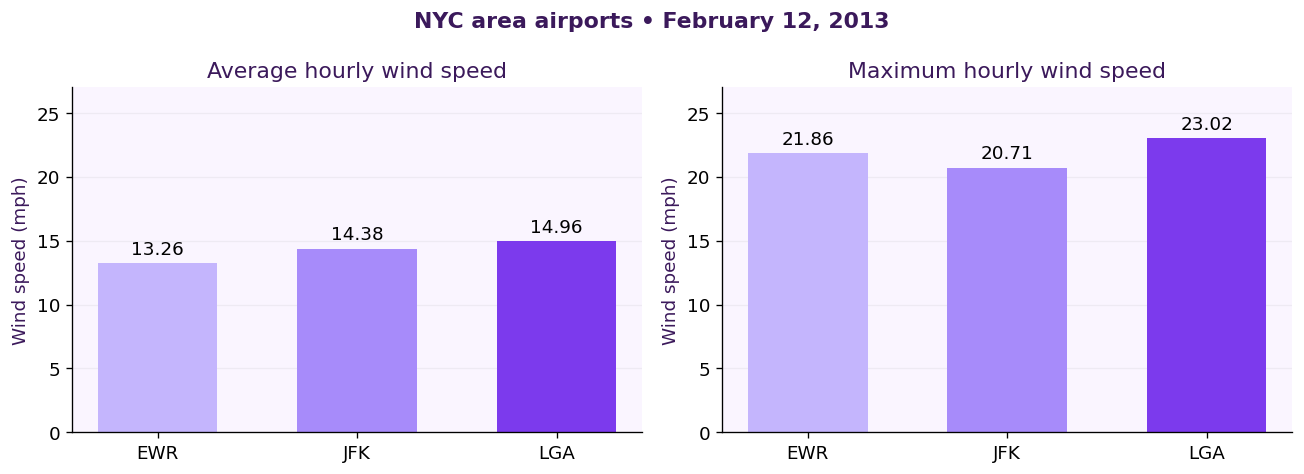

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_data = summary.reindex(["EWR", "JFK", "LGA"])
colors = [LIGHT_PURPLE, "#A78BFA", PURPLE]
for ax, column, title in zip(
    axes,
    ["mean_wind_mph", "max_wind_mph"],
    ["Average hourly wind speed", "Maximum hourly wind speed"],
):
    bars = ax.bar(plot_data.index, plot_data[column], color=colors, width=0.6)
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set(title=title, ylabel="Wind speed (mph)")
    ax.set_ylim(0, 27)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
fig.suptitle("NYC area airports • February 12, 2013", color=DARK_PURPLE, fontweight="bold")
fig.tight_layout()
plt.show()

### Answer 3

**LaGuardia Airport (LGA) had the windiest weather** under the chosen daily-mean definition after excluding Newark's invalid measurement.

| Airport | Valid hourly speeds | Mean wind speed (mph) | Maximum hourly speed (mph) |
|:--|--:|--:|--:|
| LGA | 24 | 14.960 | 23.016 |
| JFK | 24 | 14.385 | 20.714 |
| EWR | 23 | 13.259 | 21.865 |

LaGuardia also has the highest valid maximum hourly speed. The common-hour comparison provides a sensitivity check for Newark's missing hour. These are recorded hourly wind speeds, not a claim about the day's strongest gust.

## 7. Conclusion

The reviewed data identifies BRW as northernmost, EPM as easternmost under the stated west-to-east convention, and LGA as the windiest New York area airport on February 12, 2013. SYA is the alternative easternmost result if the definition is greatest signed longitude.

This exercise shows why a sorted table alone is not enough. Geographic research revealed unreliable airport coordinates, and inspection of hourly observations revealed an invalid wind speed. Documenting those decisions makes the results easier to evaluate and reproduce.

## References

Sources checked October 4, 2026.

1. [nycflights13 original CSV source directory](https://github.com/hadley/nycflights13/tree/master/data-raw).
2. [nycflights13 weather documentation: stations and units](https://nycflights13.tidyverse.org/reference/weather.html).
3. [Alaska DOT: Barrow Airport Emergency Plan, facility description, page 4-1](https://dot.alaska.gov/stwdav/documents/AEP/BRW-AEP.pdf).
4. [City of Eastport: Municipal Airport](https://eastport-me.gov/206/Municipal-Airport).
5. [City of Keene: Dillant-Hopkins Airport](https://keenenh.gov/airport/).
6. [AirNav: FAA information for EEN](https://www.airnav.com/airport/KEEN).
7. [City of San Diego: Montgomery-Gibbs Executive Airport](https://www.sandiego.gov/airports/montgomery).
8. [Phoenix Deer Valley Airport: Directions](https://www.deervalleyairport.com/about-dvt-airport/directions/).
9. [Alaska DEC: Eareckson Air Station SS12](https://dec.alaska.gov/Applications/SPAR/PublicMVC/CSP/SiteReport/65).